# 08 - Entrenamiento de la CNN

## Objetivo
ntrenar una red ResNet18 preentrenada (transfer learning) para clasificar melanoma vs nevo. Se usa el conjunto de validacion (separado de train) para elegir el mejor momento de parada.

## 1. Importación y carga de datos


In [8]:
import sys
sys.path.append("..")

from pathlib import Path
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from src.utils import fijar_semillas, SEED
from src.dataset import LesionDataset, get_transforms
from src.modelo import crear_modelo, congelar_base, descongelar_ultimo_bloque
from src.entrenamiento import entrenar_epoca, evaluar

fijar_semillas()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

PROCESSED = Path("../data/processed")
MODELOS = Path("../models")
MODELOS.mkdir(exist_ok=True)

train_df = pd.read_csv(PROCESSED / "train_cnn.csv")
val_df = pd.read_csv(PROCESSED / "val_cnn.csv")

gen = torch.Generator().manual_seed(SEED)
dl_train = DataLoader(LesionDataset(train_df, get_transforms(True)),
                      batch_size=32, shuffle=True, num_workers=0, generator=gen)
dl_val = DataLoader(LesionDataset(val_df, get_transforms(False)),
                    batch_size=32, shuffle=False, num_workers=0)
print(len(train_df), len(val_df))

Dispositivo: cpu
785 197


## 2. Modelo y fase 1: entrenamiento de la capa final

In [9]:
modelo = crear_modelo().to(device)
congelar_base(modelo)

criterio = nn.BCEWithLogitsLoss()
optimizador = torch.optim.Adam(
    [p for p in modelo.parameters() if p.requires_grad], lr=1e-3
)

historial = []
mejor_loss = float("inf")

for epoca in range(1, 9):
    loss_tr = entrenar_epoca(modelo, dl_train, criterio, optimizador, device)
    val = evaluar(modelo, dl_val, criterio, device)
    historial.append({"fase": 1, "epoca": epoca, "loss_train": loss_tr, **{f"val_{k}": v for k, v in val.items()}})
    print(f"[F1] época {epoca}: train {loss_tr:.3f} | val loss {val['loss']:.3f} "
          f"recall {val['recall']:.3f} f1 {val['f1_macro']:.3f}")
    if val["loss"] < mejor_loss:
        mejor_loss = val["loss"]
        torch.save(modelo.state_dict(), MODELOS / "cnn_resnet18.pt")

[F1] época 1: train 0.602 | val loss 0.573 recall 1.000 f1 0.705
[F1] época 2: train 0.461 | val loss 0.463 recall 0.990 f1 0.806
[F1] época 3: train 0.422 | val loss 0.478 recall 1.000 f1 0.794
[F1] época 4: train 0.406 | val loss 0.454 recall 1.000 f1 0.811
[F1] época 5: train 0.394 | val loss 0.471 recall 1.000 f1 0.800
[F1] época 6: train 0.387 | val loss 0.450 recall 1.000 f1 0.806
[F1] época 7: train 0.365 | val loss 0.460 recall 1.000 f1 0.806
[F1] época 8: train 0.358 | val loss 0.417 recall 0.980 f1 0.813


## 3. Fase 2: ajuste fino

In [10]:
modelo.load_state_dict(torch.load(MODELOS / "cnn_resnet18.pt"))
descongelar_ultimo_bloque(modelo)

optimizador = torch.optim.Adam(
    [p for p in modelo.parameters() if p.requires_grad], lr=1e-4
)

sin_mejora = 0
for epoca in range(1, 13):
    loss_tr = entrenar_epoca(modelo, dl_train, criterio, optimizador, device)
    val = evaluar(modelo, dl_val, criterio, device)
    historial.append({"fase": 2, "epoca": epoca, "loss_train": loss_tr, **{f"val_{k}": v for k, v in val.items()}})
    print(f"[F2] época {epoca}: train {loss_tr:.3f} | val loss {val['loss']:.3f} "
          f"recall {val['recall']:.3f} f1 {val['f1_macro']:.3f}")
    if val["loss"] < mejor_loss:
        mejor_loss, sin_mejora = val["loss"], 0
        torch.save(modelo.state_dict(), MODELOS / "cnn_resnet18.pt")
    else:
        sin_mejora += 1
        if sin_mejora >= 4:
            print("Parada temprana")
            break

[F2] época 1: train 0.357 | val loss 0.576 recall 0.990 f1 0.784
[F2] época 2: train 0.313 | val loss 0.382 recall 0.908 f1 0.811
[F2] época 3: train 0.243 | val loss 0.489 recall 0.949 f1 0.781
[F2] época 4: train 0.213 | val loss 0.542 recall 0.969 f1 0.808
[F2] época 5: train 0.201 | val loss 0.405 recall 0.908 f1 0.821
[F2] época 6: train 0.190 | val loss 0.481 recall 0.959 f1 0.841
Parada temprana


## 4. Curvas de entrenamiento

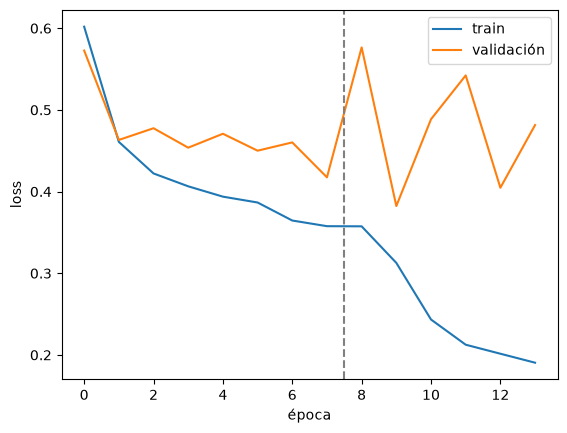

In [11]:
h = pd.DataFrame(historial)
h.to_csv(MODELOS / "historial_cnn.csv", index=False)

plt.plot(h["loss_train"].values, label="train")
plt.plot(h["val_loss"].values, label="validación")
plt.axvline(h[h["fase"] == 1].shape[0] - 0.5, color="gray", linestyle="--")
plt.xlabel("época"); plt.ylabel("loss"); plt.legend()
plt.show()